# Stage 3 — full hidden-layer ratio experiment

**Research question:** How does hidden-layer width ratio affect the accuracy and trainability of original-initialization IMP tickets at approximately fixed initial parameter count?

The protocol is locked to Stage 2.6: MNIST 55,000/5,000/10,000, split seed 42; A 162–421, B 200–204, C 231–77; model seeds 0/1/2; Adam 0.0012, batch 60, Gaussian Glorot; **10,000 fixed updates per stage, primary validation every 100**, 12 layer-wise survivor-pruning rounds (20% hidden, 10% output), original-initialization rewind and fresh Adam. Final weights determine masks; no early stopping or adaptive protocol changes.

All **39 seed-0 stages are reused read-only** from approved pilots. Only six missing seed-1/seed-2 combinations (**78 new stages**) may train. The held-out test set remains unevaluated. Random-reinitialization controls are proposed and costed, not run. All new outputs are under `reports/stage3/`.

This is a reduced-budget extension: the original paper used 50,000 updates per stage. Use the project Python kernel from the repository root. Completed-stage checkpoints resume compatible runs; completed studies skip all training. On Windows, process spawning is managed by the standalone runner's main guard, not notebook multiprocessing.

In [1]:
import os, sys, json, subprocess, tempfile, time
from pathlib import Path
os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "lottery-stage3-mpl"))
import pandas as pd
from IPython.display import display, Image, Markdown
from filelock import FileLock, Timeout
from stage3_runner import REPORT
REPORT.mkdir(parents=True, exist_ok=True)
lock_path = REPORT / "protocol.lock.json"
if lock_path.exists():
    display(json.loads(lock_path.read_text())["protocol"])
print("Only seeds 1 and 2 may train; seed 0 is never submitted.")

{'architectures': {'A': [162, 421], 'B': [200, 204], 'C': [231, 77]},
 'model_seeds': [0, 1, 2],
 'new_model_seeds': [1, 2],
 'split_seed': 42,
 'rounds': 12,
 'iterations': 10000,
 'eval_interval': 100,
 'trace_interval': None,
 'learning_rate': 0.0012,
 'batch_size': 60,
 'hidden_pruning_rate': 0.2,
 'output_pruning_rate': 0.1,
 'control': False,
 'device': 'cpu',
 'num_threads': 1,
 'preload_tensors': True,
 'data_dir': 'datasets',
 'download': False}

Only seeds 1 and 2 may train; seed 0 is never submitted.


## Execute missing combinations or attach to the active runner

Three isolated spawned worker processes each use one PyTorch CPU thread. They do not share RNG state. If a controller is already running, this cell observes it rather than launching duplicate writers. If interrupted, rerunning resumes the latest committed stages. If all six runs are complete, this cell does not retrain or overwrite their measured wall time.

In [2]:
execution_path = REPORT / "execution.json"
def state():
    return json.loads(execution_path.read_text()) if execution_path.exists() else {}
def runner_active():
    try:
        with FileLock(str(REPORT / "runner.lock"), timeout=0):
            return False
    except Timeout:
        return True
if state().get("status") != "complete":
    if runner_active():
        last_count = -1
        while runner_active():
            current = state()
            completed = len(list((REPORT / "runs").glob("*/*/stage*_complete.json")))
            if completed != last_count:
                print(f"New committed stages: {completed}/78", flush=True)
                last_count = completed
            if current.get("status") == "complete":
                break
            time.sleep(10)
        if state().get("status") != "complete":
            raise RuntimeError("Runner stopped before completion; rerun this cell to resume committed stages.")
    else:
        with (REPORT / "notebook_runner.log").open("a") as log:
            subprocess.run([sys.executable, "stage3_runner.py", "--workers", "3"],
                           stdout=log, stderr=subprocess.STDOUT, check=True)
execution = state()
assert execution["status"] == "complete" and len(execution["completed"]) == 6
print("All six missing runs complete; all 39 seed-0 stages reused.")
display(pd.DataFrame(execution["completed"]))
print("Parallel execution wall minutes:", execution["elapsed_seconds"] / 60)

All six missing runs complete; all 39 seed-0 stages reused.


,architecture,seed,run_directory,stages,elapsed_this_call_seconds
0,B,1,/workspace/Advanced-topics-in-Deep-learning/re...,13,776.555892
1,C,1,/workspace/Advanced-topics-in-Deep-learning/re...,13,898.276160
2,A,1,/workspace/Advanced-topics-in-Deep-learning/re...,13,974.456671
3,A,2,/workspace/Advanced-topics-in-Deep-learning/re...,13,1003.942685
4,C,2,/workspace/Advanced-topics-in-Deep-learning/re...,13,880.888559
5,B,2,/workspace/Advanced-topics-in-Deep-learning/re...,13,1050.877743


Parallel execution wall minutes: 32.567040200899996


## Assemble and verify 117 comparable stages

C/seed0 originally recorded every-100 diagnostics with a 500-step selector. The approved fine-grid recomputation is reused; no original file or trained mask is changed. Other runs use primary 100-step evaluation directly. Every reported accuracy is at minimum validation loss, not maximum accuracy. Changes are computed relative to the same architecture/seed's own dense baseline before aggregation.

In [3]:
import stage3_analysis as analysis
results, history, summary, common, common_summary, pairs = analysis.collect_study()
assert len(results) == 117 and len(history) == 11700
assert results.groupby(["architecture", "seed"]).size().eq(13).all()
assert results.eval_interval.eq(100).all()
verification = analysis.verify_study()
analysis.write_reproducibility_report(results)
display(verification)
display(results[["architecture", "seed", "stage", "remaining_parameters", "best_iteration",
    "best_validation_accuracy", "accuracy_change_pp", "budget_concern"]])
print("Late-budget warnings in new seeds:")
display(results[(results.seed != 0) & results.budget_concern])

{'status': 'verified',
 'combinations': 9,
 'stages': 117,
 'new_stages': 78,
 'reused_seed0_stages': 39,
 'prior_files_unchanged': 610,
 'test_set_evaluated': False,
 'controls_executed': 0,
 'core_sha256': {'experiment.py': '73b528d2421d6fbd1ab18ce85dd810002abbed87a4d443fa8a9017ccb40681b4',
  'train.py': 'ba0e9d92a320437a11eaf977f5b225e586e653e1483c96b094fe823b2a742329',
  'pruning.py': 'f182e00eab6cd8289fa1e9ab9a9dc64b6d0f393665af716f844d968073329781',
  'models.py': 'af362604ad3395aaed0976f6a2d131d99207b82ccc9d45ded08bd3f9417ca9ec',
  'data.py': '4b23113ec2ccff7417347e745076da46aa66a53e86c4e1527799fe3794166673',
  'checkpoints.py': '71688555e1cc0dfe4f8a15318e42a50ee38e239883ae338d22eb3369d318665e'},
 'execution_workers': 3,
 'execution_wall_seconds': 1954.0224120539997,
 'C_seed0_original_primary500_with_diagnostic100': True,
 'C_seed0_uses_approved_fine100_metrics': True,
 'source_configs_not_modified': True,
 'details': [{'architecture': 'A',
   'seed': 0,
   'stages_verified': 1

,architecture,seed,stage,remaining_parameters,best_iteration,best_validation_accuracy,accuracy_change_pp,budget_concern
0,A,0,0,200013,2500,0.9786,-0.00,False
1,A,0,1,160551,2300,0.9762,-0.24,False
2,A,0,2,128940,2600,0.9820,0.34,False
3,A,0,3,103612,2600,0.9812,0.26,False
4,A,0,4,83316,2500,0.9796,0.10,False
...,...,...,...,...,...,...,...,...
112,C,2,8,34023,3200,0.9808,0.12,False
113,C,2,9,27316,2700,0.9810,0.14,False
114,C,2,10,21948,3200,0.9816,0.20,False
115,C,2,11,17650,3200,0.9814,0.18,False


Late-budget warnings in new seeds:


,architecture,seed,initialization_seed,split_seed,stage,condition,iterations,eval_interval,parameters,total_weights,...,late_loss_decreasing,late_global_min_improvement,final_loss_within_2pct_of_best,budget_concern,origin,remaining_parameters,high_sparsity_concern,accuracy_change_pp,source_run_directory,reused_seed0
52,B,1,1,42,0,dense,10000,100,200054,199640,...,False,0.000622,False,True,new_Stage3,200054,False,-0.0,/workspace/Advanced-topics-in-Deep-learning/re...,False


## Means, sample SD and individual seed trajectories

Bands show **mean ± one sample standard deviation (ddof=1), n=3**, not a confidence interval. Faint lines show individual seeds. Seed variability represents initialization/shuffle effects on the same fixed validation split; it does not quantify population/test uncertainty. Repeated rounds are not independent replicates. Actual active parameter counts include surviving weights and dense biases; identical pruning rounds are not assumed parameter-matched.

,architecture,stage,remaining_parameters,best_validation_accuracy_mean,best_validation_accuracy_std,accuracy_change_pp_mean,accuracy_change_pp_std,best_iteration_mean,best_iteration_std
0,A,0,200013,0.979333,0.000808,0.000000e+00,0.000000,4300.000000,1637.070554
6,A,6,54008,0.980000,0.001114,6.666667e-02,0.192180,2266.666667,351.188458
12,A,12,15203,0.979333,0.000115,3.700743e-15,0.091652,2833.333333,416.333200
13,B,0,200054,0.977933,0.001102,0.000000e+00,0.000000,5033.333333,3106.981386
19,B,6,53301,0.981000,0.001114,3.066667e-01,0.197315,2400.000000,458.257569
25,B,12,14575,0.980933,0.000503,3.000000e-01,0.060000,2966.666667,305.505046
26,C,0,199979,0.979533,0.000702,0.000000e+00,0.000000,4600.000000,458.257569
32,C,6,52870,0.980200,0.001200,6.666667e-02,0.162891,2466.666667,152.752523
38,C,12,14209,0.978933,0.001301,-6.000000e-02,0.103923,3966.666667,378.593890


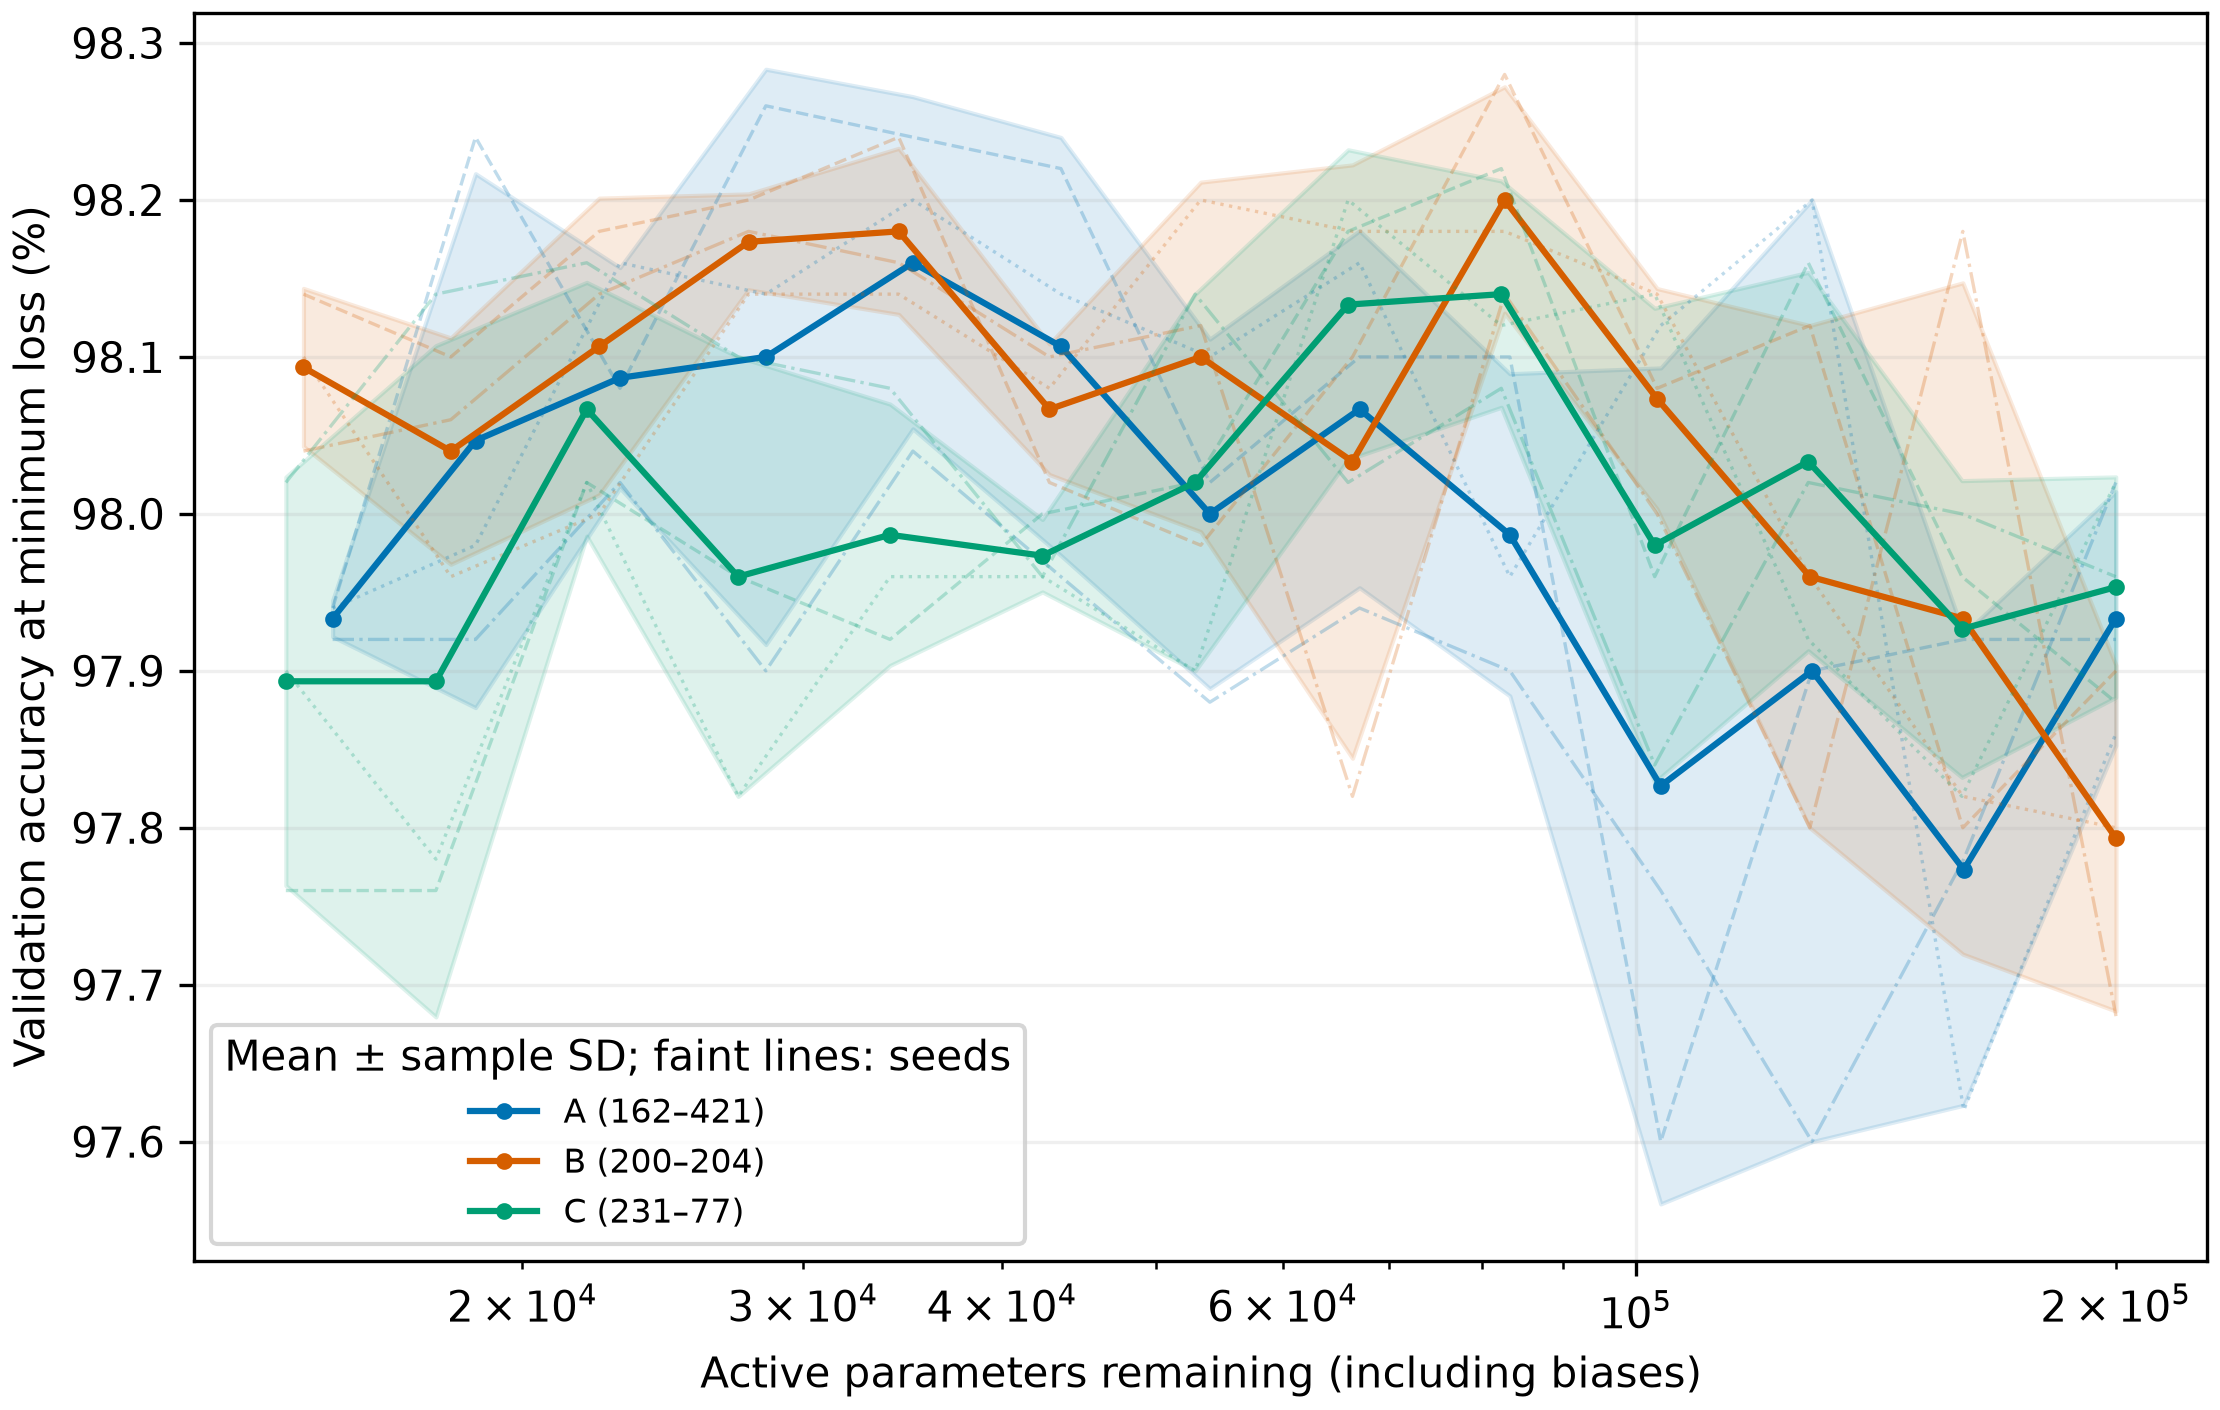

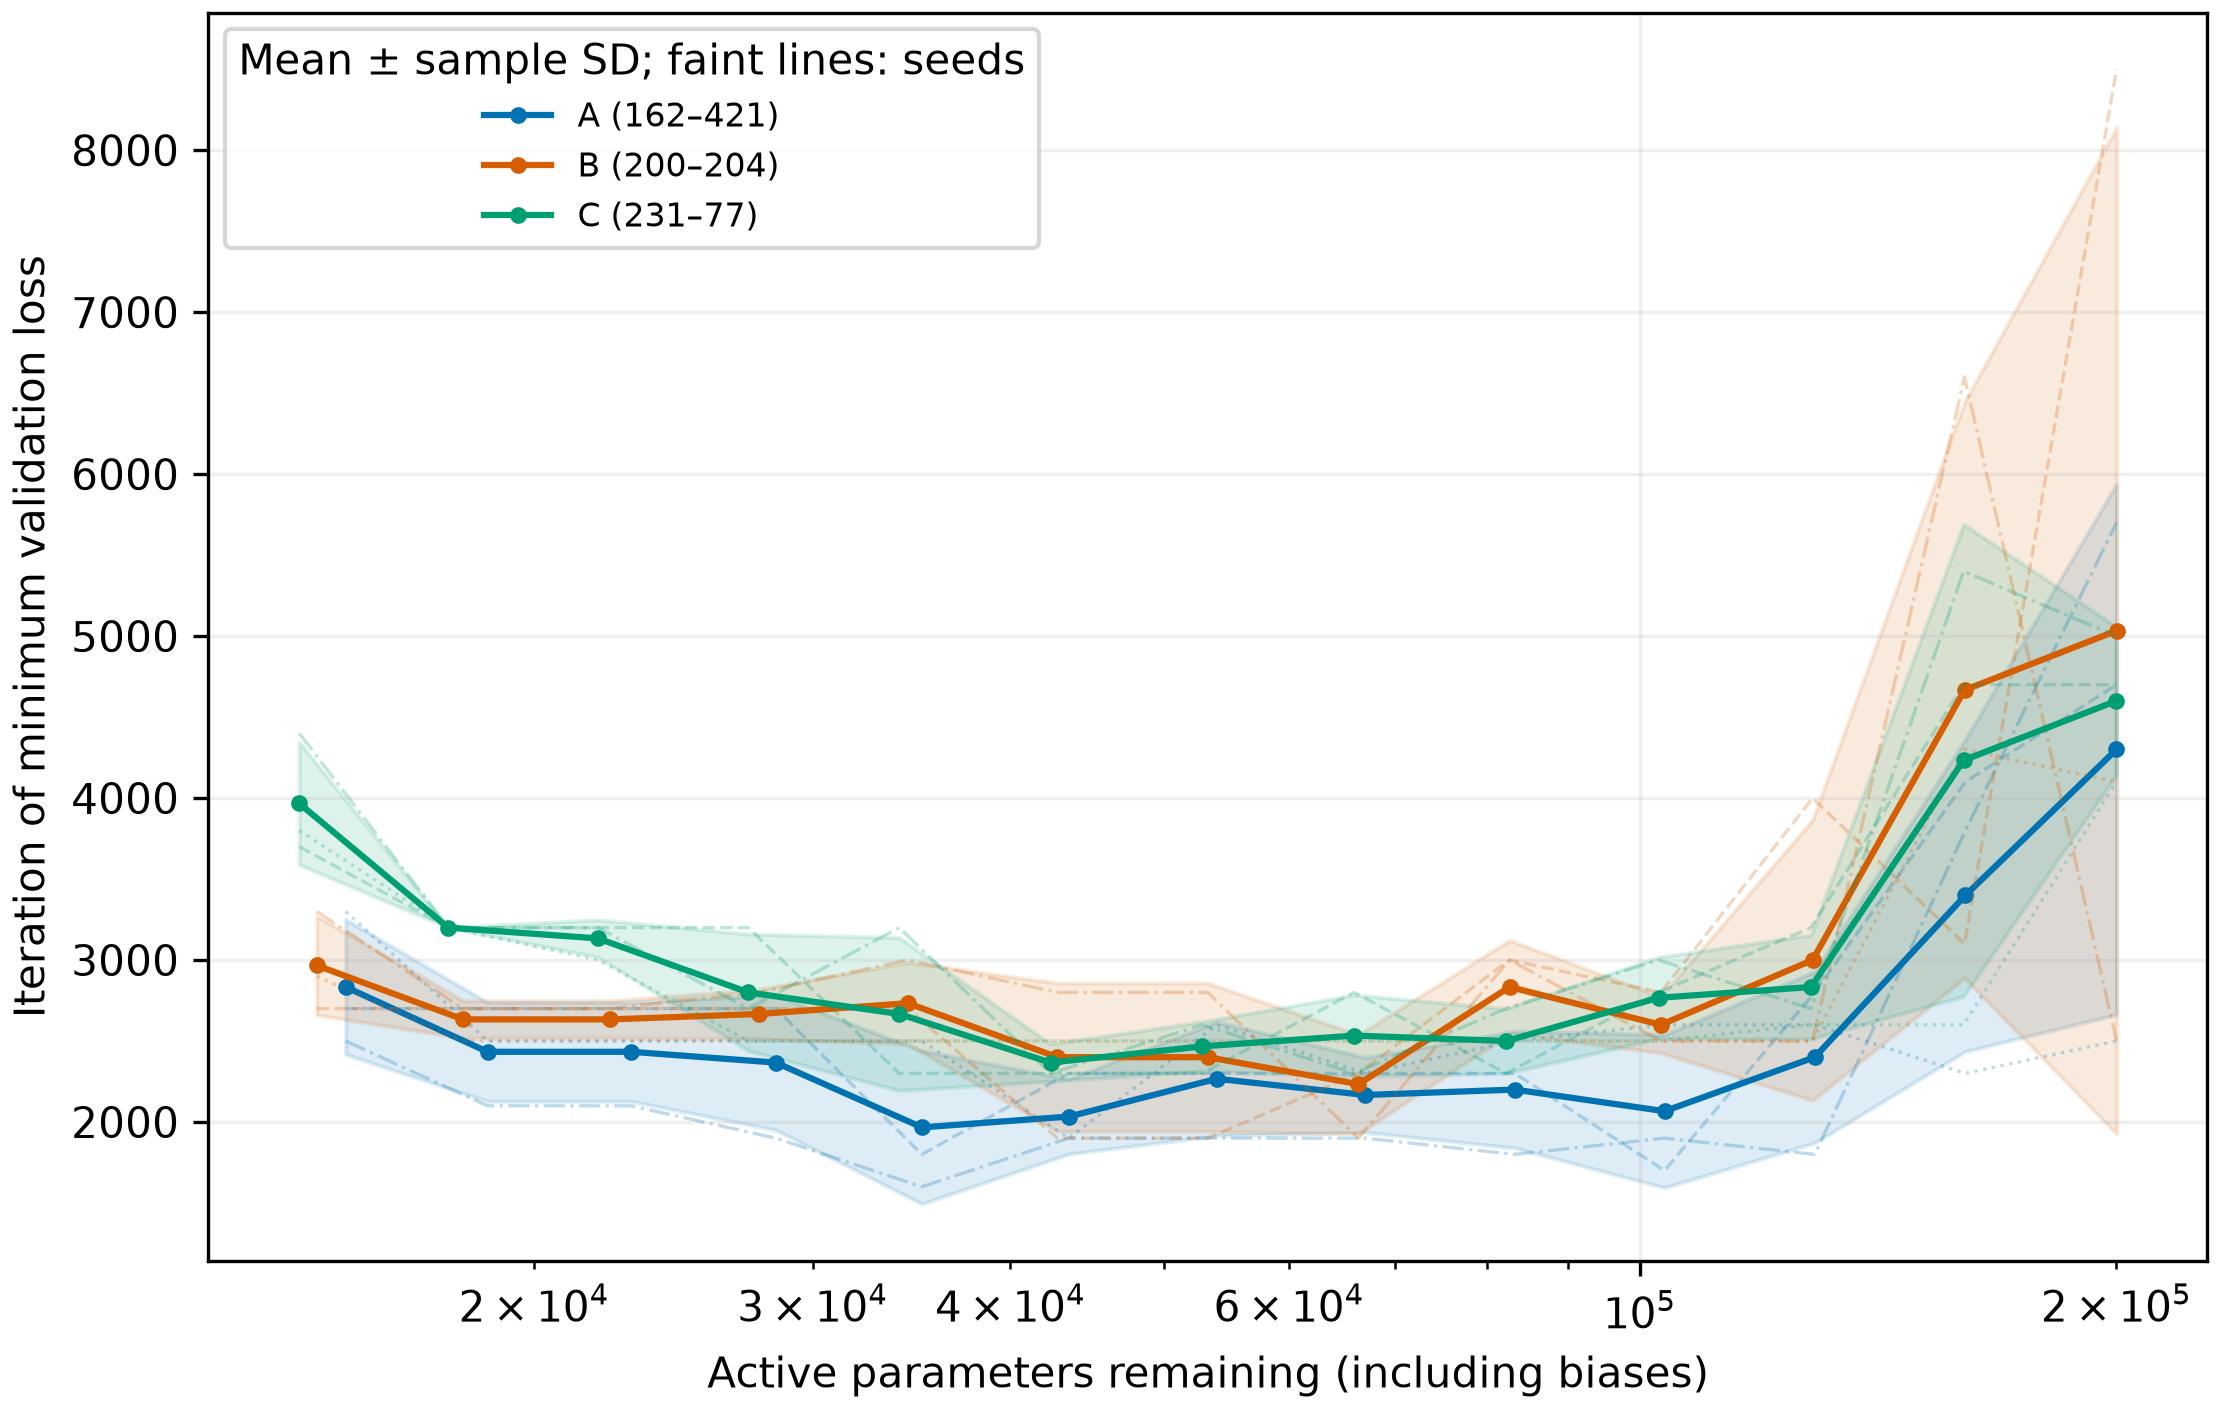

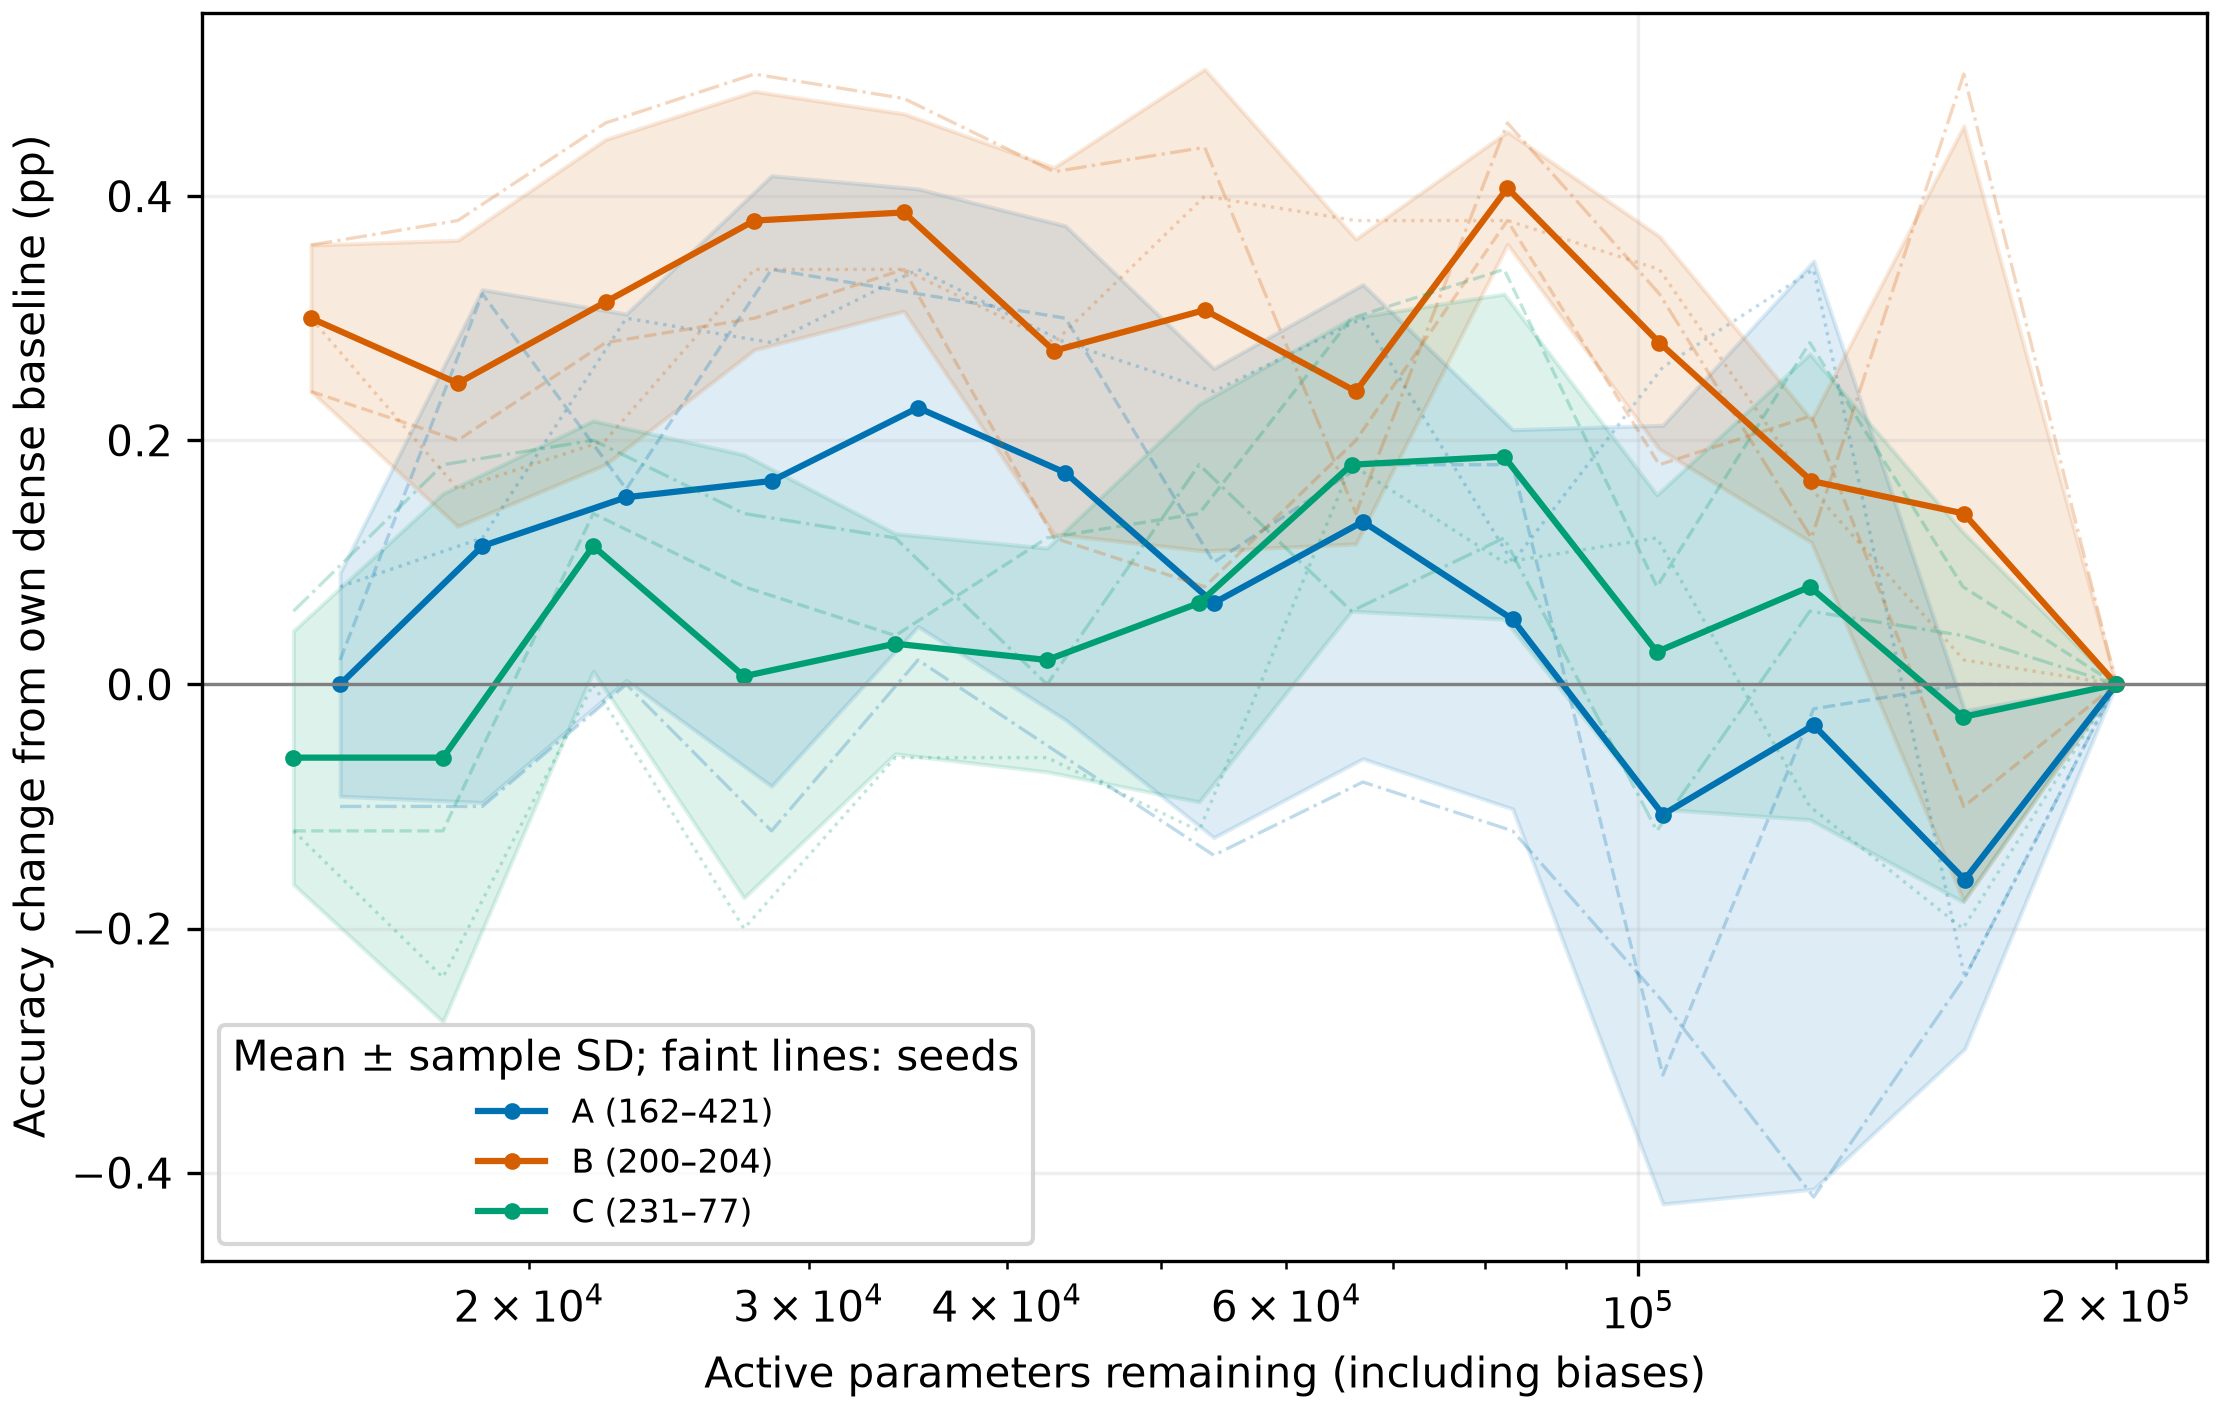

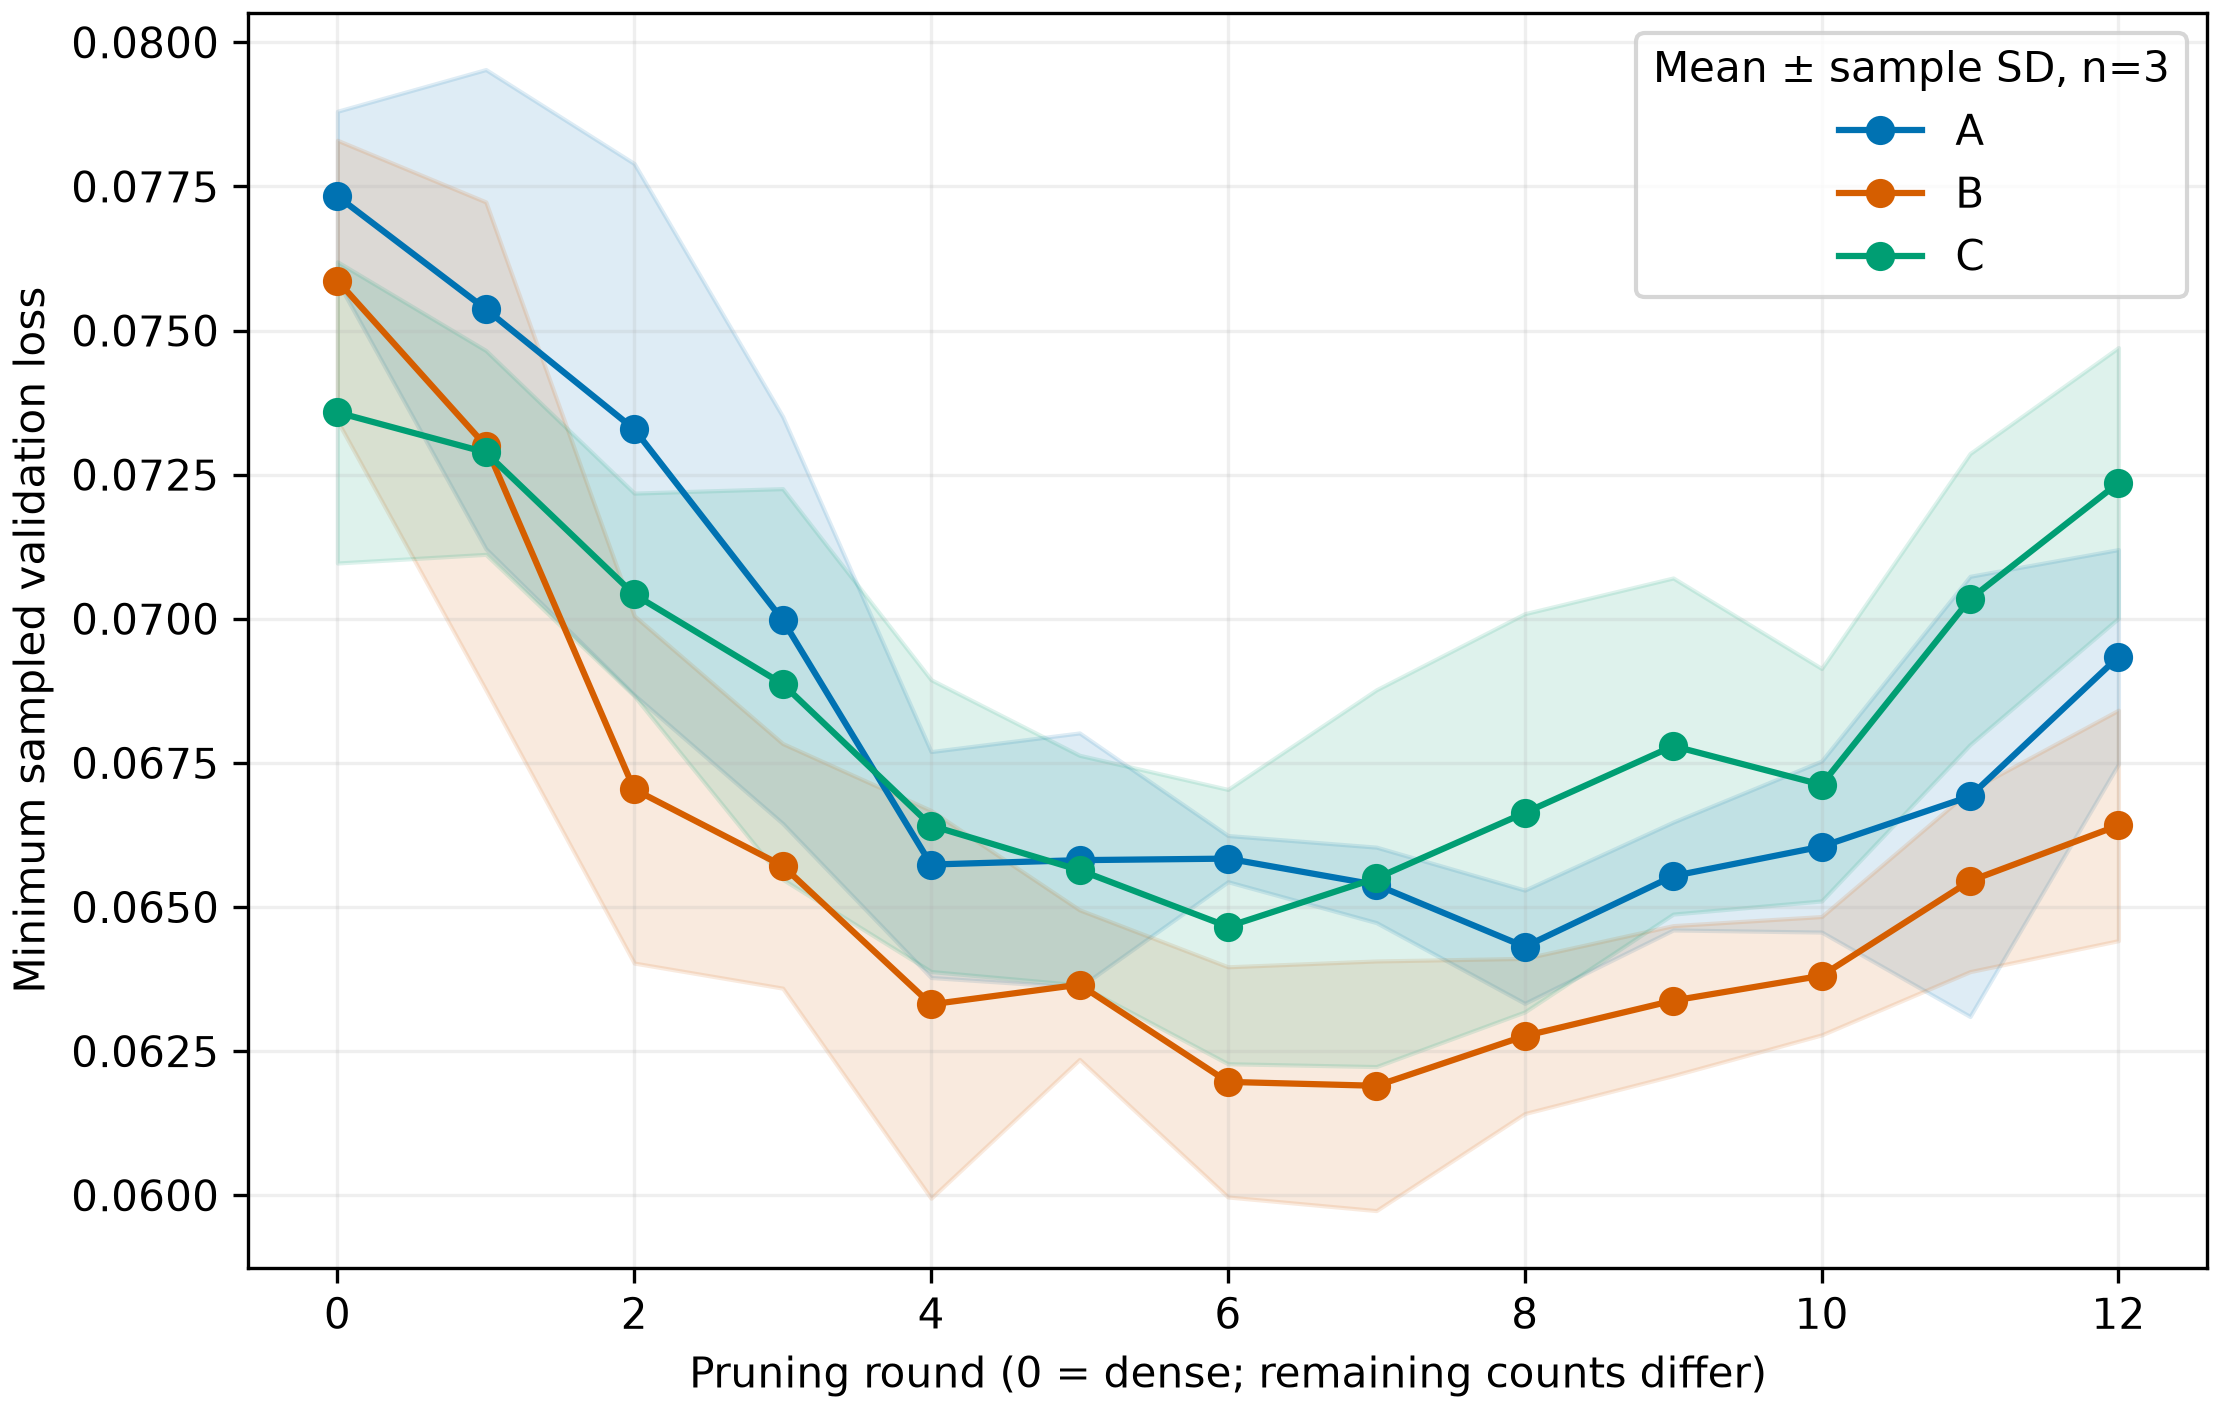

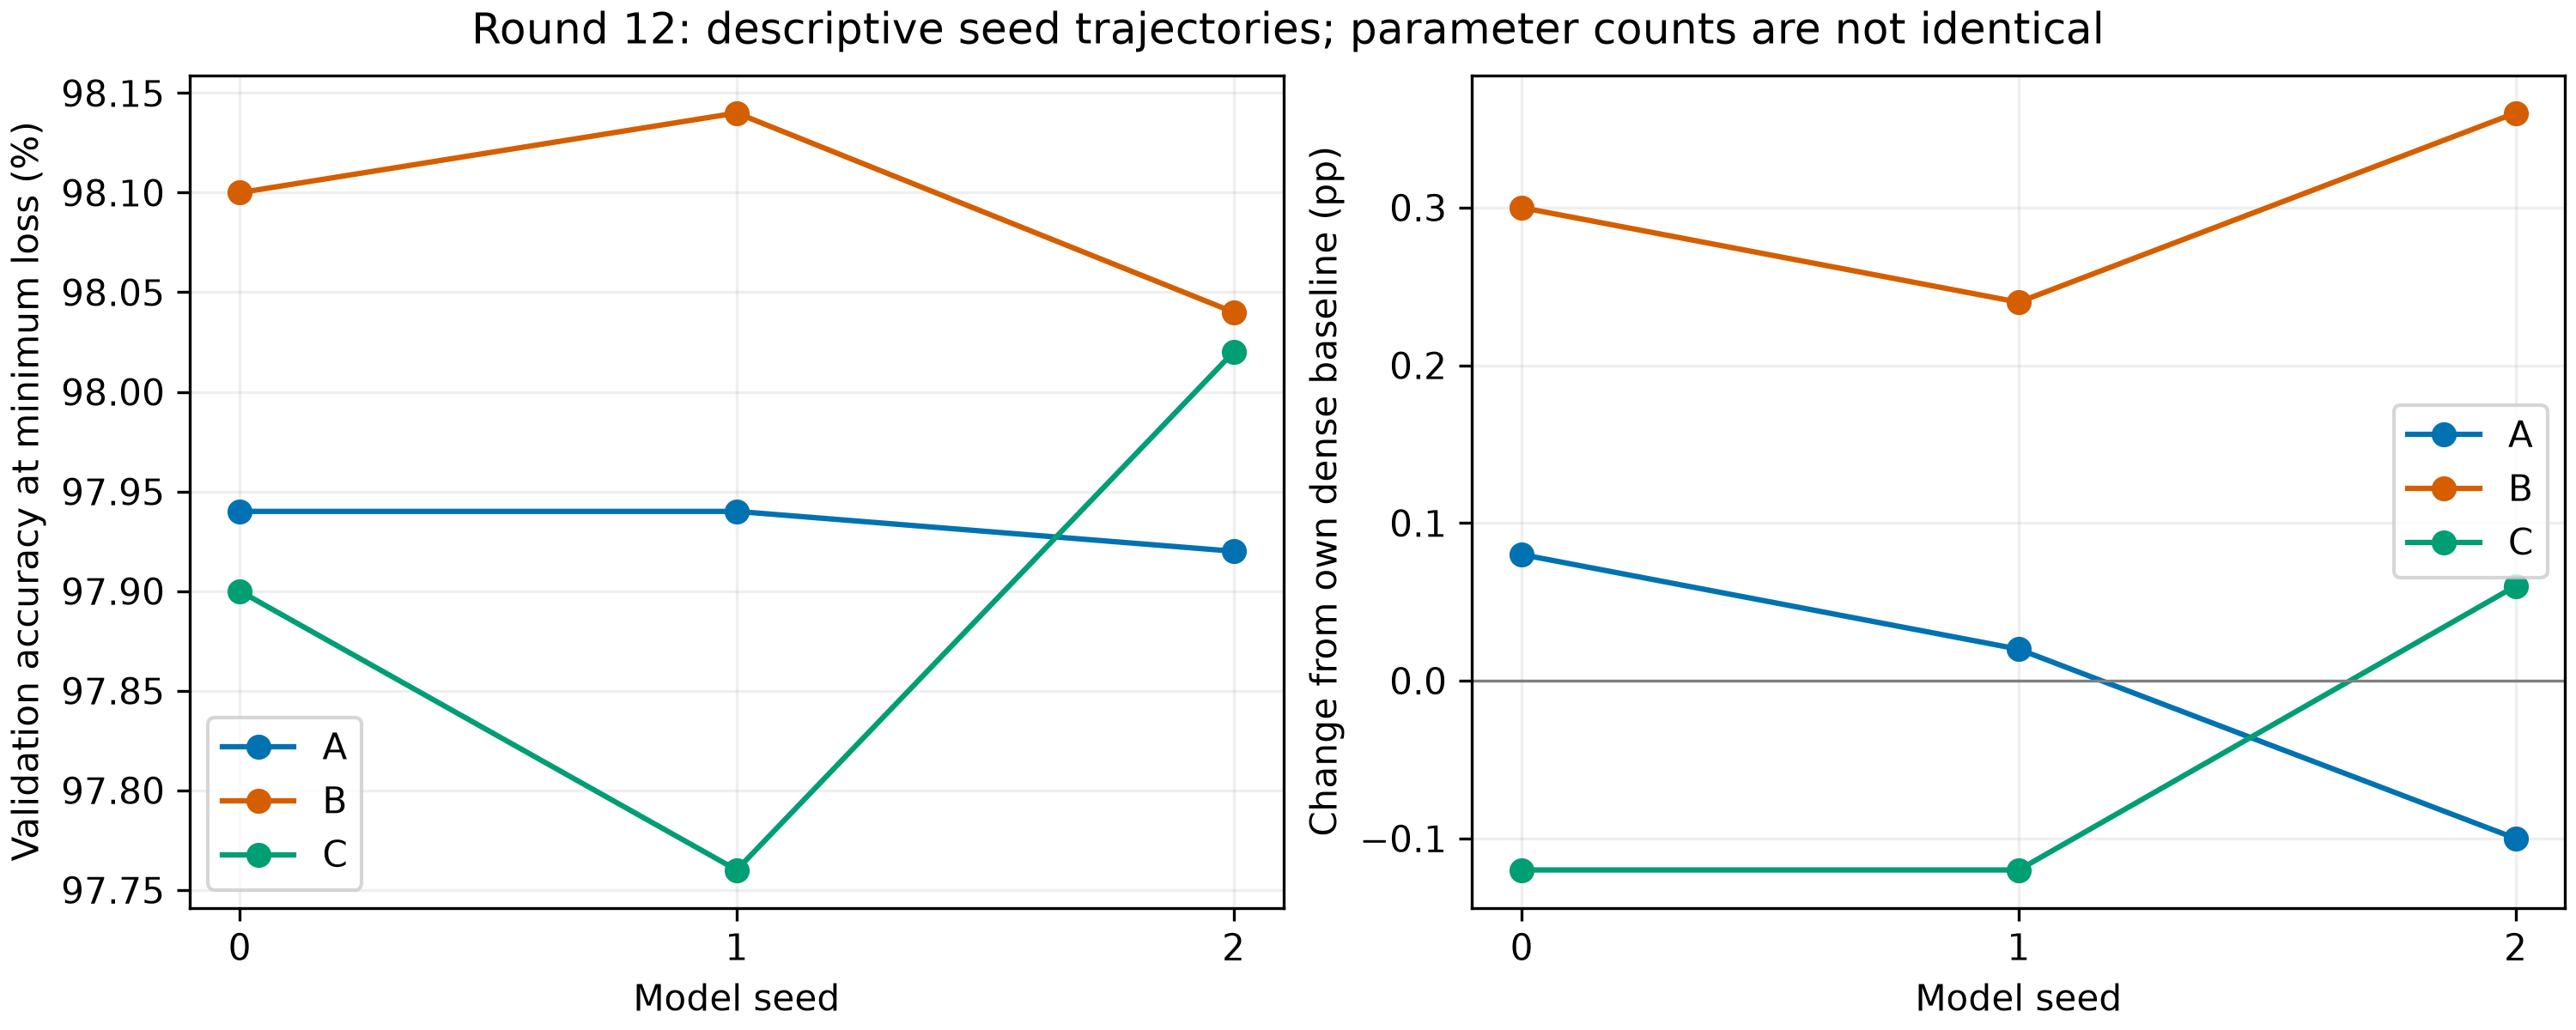

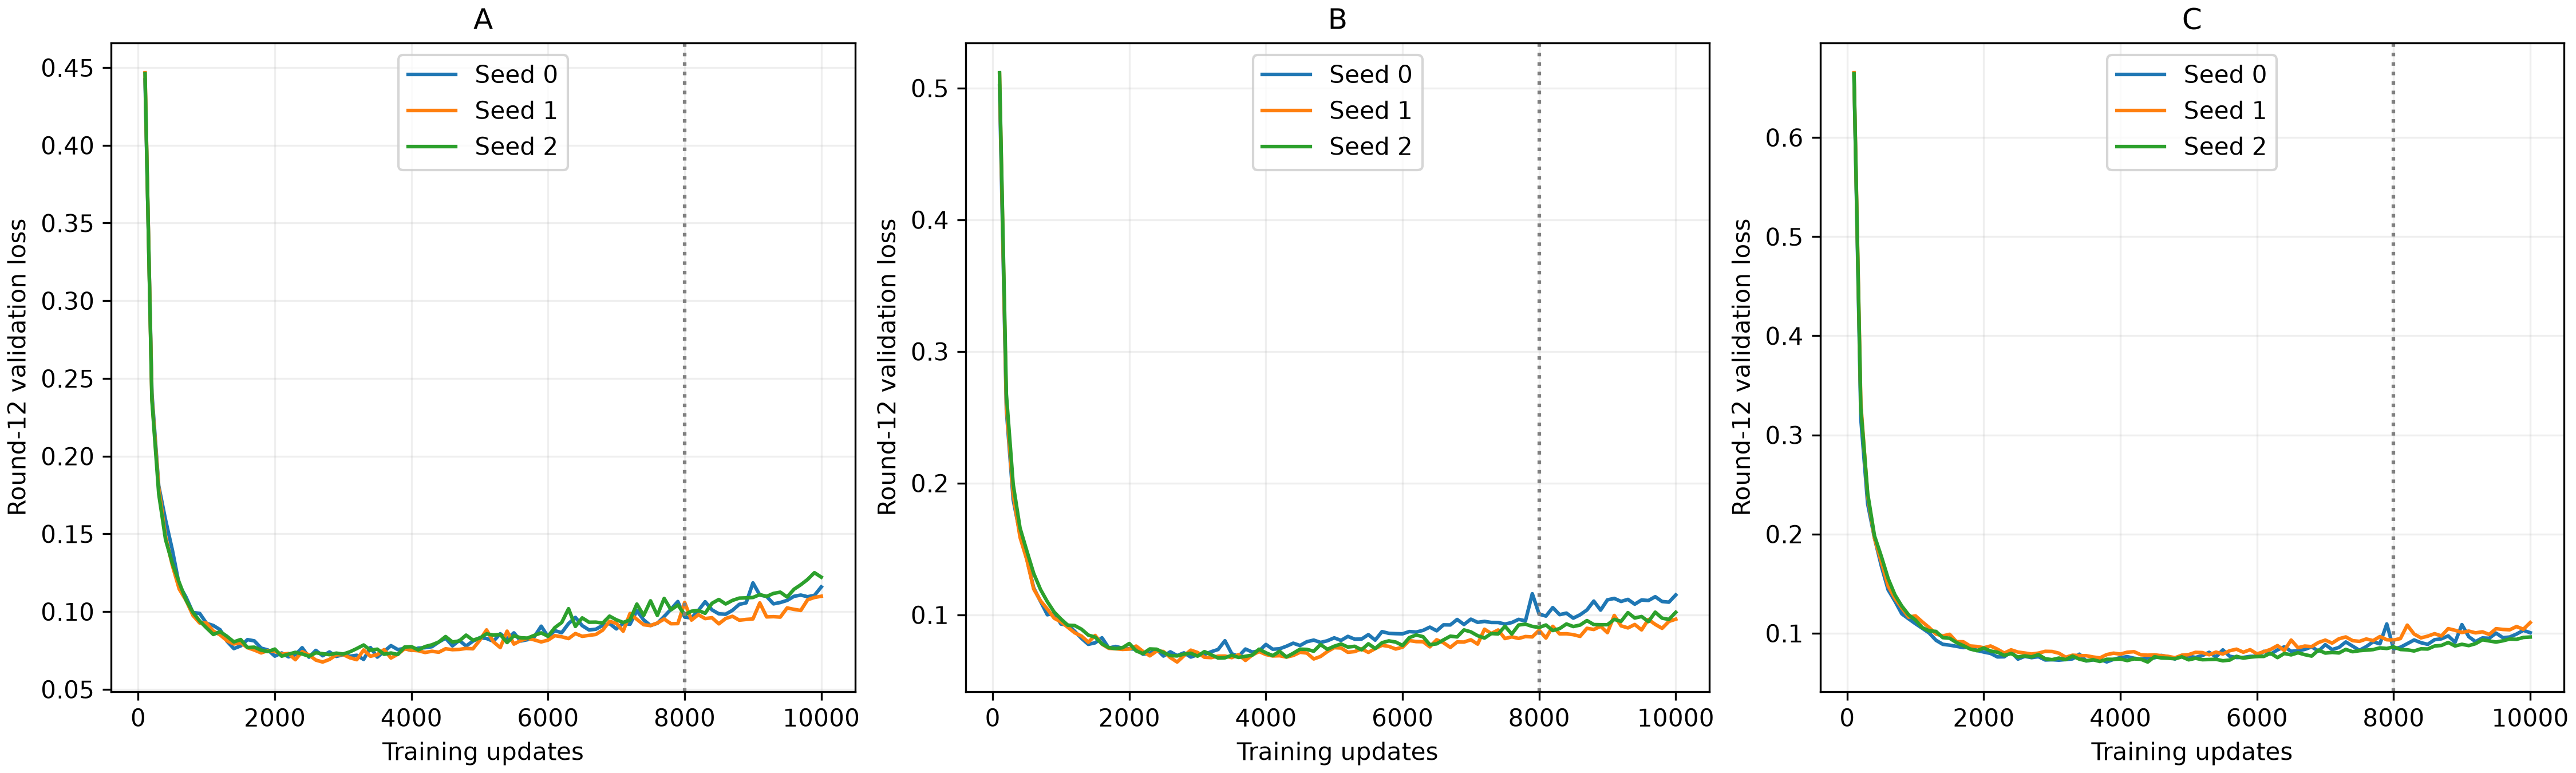

In [4]:
analysis.save_figures(results, history, summary)
display(summary[summary.stage.isin([0, 6, 12])][["architecture", "stage", "remaining_parameters",
    "best_validation_accuracy_mean", "best_validation_accuracy_std", "accuracy_change_pp_mean",
    "accuracy_change_pp_std", "best_iteration_mean", "best_iteration_std"]])
for name in ("accuracy_vs_remaining_parameters", "trainability_vs_remaining_parameters",
             "accuracy_change_vs_remaining_parameters", "validation_loss_vs_pruning_round",
             "individual_seeds_round12", "high_sparsity_validation_loss_by_seed"):
    display(Image(filename=str(REPORT / "figures" / f"{name}.png")))

## Descriptive comparisons at common high-sparsity budgets

The 16k/20k/30k/50k/100k/150k budgets were chosen within shared measured support. Each seed's curve is interpolated linearly in log(active parameter count), with no extrapolation. These are approximations between observed masks, **not new trained networks or exact matching checkpoints**. Interpret them alongside the raw actual-count curves. Pairwise seed-index contrasts remain descriptive; no significance test is claimed from only three seeds.

In [5]:
display(common_summary[common_summary.parameter_budget.isin([16000, 20000])])
display(pairs[pairs.parameter_budget.isin([16000, 20000])])
print("Per-seed observations and interpolation brackets are saved in CSV.")
display(pd.read_csv(REPORT / "runtime.csv"))
print("Controls are estimates only, not executions:")
display(pd.read_csv(REPORT / "control_cost_estimate.csv"))

,architecture,parameter_budget,validation_accuracy_mean,validation_accuracy_std,validation_accuracy_min,validation_accuracy_max,accuracy_change_pp_mean,accuracy_change_pp_std,accuracy_change_pp_min,accuracy_change_pp_max,best_iteration_mean,best_iteration_std,best_iteration_min,best_iteration_max,seed_count,nonnegative_change_seeds
0,A,16000,0.979614,0.000482,0.979200,0.980143,0.028051,0.110917,-0.100000,0.094252,2734.330492,351.757290,2400.997158,3101.994317,3,2
1,A,20000,0.980597,0.001192,0.979525,0.981880,0.126323,0.173752,-0.067526,0.268042,2433.333333,305.505046,2100.000000,2700.000000,3,2
6,B,16000,0.980700,0.000458,0.980387,0.981225,0.276638,0.080191,0.222478,0.368761,2820.653528,187.923293,2700.000000,3037.176350,3,3
7,B,20000,0.980722,0.000829,0.979793,0.981386,0.278830,0.124619,0.179298,0.418595,2633.333333,115.470054,2500.000000,2700.000000,3,3
12,C,16000,0.978933,0.001707,0.977600,0.980857,-0.060000,0.164132,-0.185690,0.125690,3546.979641,171.344833,3426.291070,3743.098569,3,1
13,C,20000,0.979927,0.001375,0.979091,0.981515,0.039413,0.147181,-0.102351,0.191471,3161.764291,66.226190,3085.292874,3200.000000,3,2


,parameter_budget,comparison,metric,seed0_difference_pp,seed1_difference_pp,seed2_difference_pp,mean_difference_pp,sample_std_difference_pp,positive_seeds,negative_seeds,inference
0,16000,A-B,validation_accuracy,-0.088774,-0.108226,-0.128761,-0.108587,0.019996,0,3,"descriptive matched seed-index contrasts, no h..."
1,16000,A-B,accuracy_change_pp,-0.148774,-0.128226,-0.468761,-0.248587,0.190953,0,3,"descriptive matched seed-index contrasts, no h..."
2,16000,A-C,validation_accuracy,0.115590,0.254252,-0.165690,0.068051,0.213969,2,1,"descriptive matched seed-index contrasts, no h..."
3,16000,A-C,accuracy_change_pp,0.275590,0.214252,-0.225690,0.088051,0.273433,2,1,"descriptive matched seed-index contrasts, no h..."
4,16000,B-C,validation_accuracy,0.204365,0.362478,-0.036929,0.176638,0.201142,2,1,"descriptive matched seed-index contrasts, no h..."
5,16000,B-C,accuracy_change_pp,0.424365,0.342478,0.243071,0.336638,0.090788,3,0,"descriptive matched seed-index contrasts, no h..."
6,20000,A-B,validation_accuracy,0.059155,0.049447,-0.146122,-0.012507,0.115816,2,1,"descriptive matched seed-index contrasts, no h..."
7,20000,A-B,accuracy_change_pp,-0.000845,0.029447,-0.486122,-0.152507,0.289316,1,2,"descriptive matched seed-index contrasts, no h..."
8,20000,A-C,validation_accuracy,0.120804,0.278923,-0.198997,0.066910,0.243475,2,1,"descriptive matched seed-index contrasts, no h..."
9,20000,A-C,accuracy_change_pp,0.280804,0.238923,-0.258997,0.086910,0.300295,2,1,"descriptive matched seed-index contrasts, no h..."


Per-seed observations and interpolation brackets are saved in CSV.


,architecture,seed,stages,training_validation_seconds,evaluation_seconds,training_validation_minutes,reused_seed0
0,A,0,13,826.182472,86.169495,13.769708,True
1,A,1,13,971.894095,108.641683,16.198235,False
2,A,2,13,1000.922490,108.176823,16.682042,False
3,B,0,13,865.010937,90.147683,14.416849,True
4,B,1,13,774.446802,82.837101,12.907447,False
5,B,2,13,1047.714731,116.590285,17.461912,False
6,C,0,13,820.420389,85.548252,13.673673,True
7,C,1,13,895.721463,101.356586,14.928691,False
8,C,2,13,877.950102,98.769080,14.632502,False


Controls are estimates only, not executions:


,study,architectures,seeds,pruning_rounds,new_control_trainings,updates_per_control,new_updates,estimated_serial_cpu_minutes,planning_minutes_plus_25_percent,executed,ticket_retraining_required,basis
0,Small initial same-mask control pilot,"A,B,C",0,"6,12",6,10000,60000,6.438350,8.047937,False,False,Matched ticket wall times; controls use same m...
1,Three-seed matched controls,"A,B,C","0,1,2","6,12",18,10000,180000,20.517303,25.646629,False,False,Matched ticket wall times; controls use same m...


In [6]:
tests = subprocess.run([sys.executable, "-m", "pytest", "-q"], capture_output=True, text=True)
(REPORT / "tests.txt").write_text(tests.stdout + tests.stderr)
print(tests.stdout)
tests.check_returncode()
from stage3_runner import preserve_previous
print("Prior files preserved:", preserve_previous())
discussion = analysis.describe_study(results, summary, common, common_summary, pairs)
display(Markdown(discussion))

........................................................................ [ 93%]
.....                                                                    [100%]
77 passed in 7.72s



Prior files preserved: 610


# Stage 3 — hidden-layer ratio experiment

The main experiment is complete: **9 architecture–seed combinations, 117 training stages, 11,700 validation observations**. Exactly **78 new stages** (seeds 1 and 2) were executed; all **39 seed-0 stages were reused**, including their original masks/checkpoints. The held-out test set and random-reinitialization controls were not evaluated/run. Final tests: **77 passed in 7.72s**.

## Protocol

MNIST 55,000 train / 5,000 validation / 10,000 held-out test; split seed 42; A 162–421, B 200–204, C 231–77; seeds 0/1/2; Adam 0.0012; batch 60; Gaussian Glorot; 10,000 fixed updates; validation every 100; 12 layer-wise pruning rounds (20% hidden, 10% output survivors), original-initialization rewind and fresh Adam. No protocol was changed in response to accuracy or warnings. **10,000 replaces the original paper's 50,000 updates**, so this is a reduced-budget extension, not an exact replication.

## Observed accuracy and trainability

| Model | Stage | Active parameters | Accuracy (%), mean ± SD | Change (pp), mean ± SD | Best iteration, mean ± SD |
|---|---:|---:|---:|---:|---:|
| A | 0 | 200,013 | 97.93 ± 0.08 | 0.00 ± 0.00 | 4300.00 ± 1637.07 |
| A | 6 | 54,008 | 98.00 ± 0.11 | 0.07 ± 0.19 | 2266.67 ± 351.19 |
| A | 12 | 15,203 | 97.93 ± 0.01 | 0.00 ± 0.09 | 2833.33 ± 416.33 |
| B | 0 | 200,054 | 97.79 ± 0.11 | 0.00 ± 0.00 | 5033.33 ± 3106.98 |
| B | 6 | 53,301 | 98.10 ± 0.11 | 0.31 ± 0.20 | 2400.00 ± 458.26 |
| B | 12 | 14,575 | 98.09 ± 0.05 | 0.30 ± 0.06 | 2966.67 ± 305.51 |
| C | 0 | 199,979 | 97.95 ± 0.07 | 0.00 ± 0.00 | 4600.00 ± 458.26 |
| C | 6 | 52,870 | 98.02 ± 0.12 | 0.07 ± 0.16 | 2466.67 ± 152.75 |
| C | 12 | 14,209 | 97.89 ± 0.13 | -0.06 ± 0.10 | 3966.67 ± 378.59 |

These are observed points, with **mean ± sample SD across three seeds**, not confidence intervals. Changes are first computed relative to each model/seed's own dense accuracy. Equal rounds leave different active parameter counts, so this table does not establish a parameter-matched winner. Full per-seed values and all rounds are in `individual_results.csv`; all 39 mean/SD rows are in `summary_mean_std.csv`. Faint figure lines show individual seed trajectories.

## Accuracy at common high-sparsity parameter budgets

| Budget (interpolated) | Model | Accuracy (%), mean ± SD | Change (pp), mean ± SD | Seeds retaining dense accuracy | Interpolated best iteration, mean ± SD |
|---:|---|---:|---:|---:|---:|
| 16,000 | A | 97.96 ± 0.05 | 0.03 ± 0.11 | 2/3 | 2734.33 ± 351.76 |
| 16,000 | B | 98.07 ± 0.05 | 0.28 ± 0.08 | 3/3 | 2820.65 ± 187.92 |
| 16,000 | C | 97.89 ± 0.17 | -0.06 ± 0.16 | 1/3 | 3546.98 ± 171.34 |
| 20,000 | A | 98.06 ± 0.12 | 0.13 ± 0.17 | 2/3 | 2433.33 ± 305.51 |
| 20,000 | B | 98.07 ± 0.08 | 0.28 ± 0.12 | 3/3 | 2633.33 ± 115.47 |
| 20,000 | C | 97.99 ± 0.14 | 0.04 ± 0.15 | 2/3 | 3161.76 ± 66.23 |

Each seed is interpolated linearly in log(active parameters), within its observed support only; these are descriptive estimates, not additional trained networks or exact-mask matches. Saved interpolation brackets document the approximation. Actual-count curves and individual observations remain the primary evidence.

- At **16,000 active parameters** (interpolated), the descriptive mean accuracy leader is **B**; the mean dense-relative retention leader is **B**. The largest mean accuracy separation is **0.177 pp**, approximately 8.8 of 5,000 validation classifications. Nonnegative dense-relative changes: A: 2/3, B: 3/3, C: 1/3. The smallest interpolated mean minimum-loss iteration is for **A**. These are descriptive comparisons, not new trained networks or held-out measurements.
- At **20,000 active parameters** (interpolated), the descriptive mean accuracy leader is **B**; the mean dense-relative retention leader is **B**. The largest mean accuracy separation is **0.079 pp**, approximately 4.0 of 5,000 validation classifications. Nonnegative dense-relative changes: A: 2/3, B: 3/3, C: 2/3. The smallest interpolated mean minimum-loss iteration is for **A**. These are descriptive comparisons, not new trained networks or held-out measurements.

Consistency of those descriptive leaders across individual seed indices:

- 16,000, validation_accuracy: individual-seed leaders/ties: A 0/3, B 2/3, C 1/3.
- 16,000, accuracy_change_pp: individual-seed leaders/ties: A 0/3, B 3/3, C 0/3.
- 16,000, best_iteration: individual-seed leaders/ties: A 2/3, B 2/3, C 0/3.
- 20,000, validation_accuracy: individual-seed leaders/ties: A 2/3, B 0/3, C 1/3.
- 20,000, accuracy_change_pp: individual-seed leaders/ties: A 1/3, B 2/3, C 0/3.
- 20,000, best_iteration: individual-seed leaders/ties: A 3/3, B 2/3, C 0/3.

## Answer to the research question

**Dense-accuracy retention:** B was the most consistent descriptive retention candidate at the two shared high-sparsity budgets. Its mean changes were +0.277 ± 0.080 pp at 16k and +0.279 ± 0.125 pp at 20k; it retained/exceeded its own dense accuracy in 3/3 and 3/3 seeds, respectively. This is a descriptive result for these seeds, not statistically established superiority.

**Absolute sparse accuracy:** at 20k active parameters the means were A 98.060 ± 0.119%, B 98.072 ± 0.083%, C 97.993 ± 0.138%. The largest separation was 0.079 pp (about 4.0 validation classifications), smaller than each architecture's measured seed SD (0.083–0.138 pp). Individual-seed accuracy leaders/ties at 20k were A 2/3, B 0/3, C 1/3. At 16k, the A-minus-B accuracy contrast was -0.109 ± 0.020 pp; it was positive in 0/3 and negative in 3/3 seed indices. Thus the descriptive ordering depends on parameter budget and seed. Dense means were A 97.93%, B 97.79%, C 97.95%; B's weaker dense baseline is important when interpreting its larger pruning gains.

**Trainability:** at the same 20k budget, interpolated minimum-loss iterations were A 2433 ± 306, B 2633 ± 115, C 3162 ± 66. C reached its minimum later than A in 3/3 seeds and later than B in 3/3 seeds. A and B tied in 2/3 seeds and A was earlier in 1/3 at this budget. This is a more consistent descriptive learning-pattern difference than the absolute-accuracy ordering. It suggests the 3:1 reference reached its best sampled loss later in these pruned runs; it is not a population-level or wall-clock speed claim. All models still trained for 10,000 updates. Common-count numbers are interpolated approximations; observed actual-count curves remain primary.

**Implication:** the data favor examining B for robust dense-relative accuracy preservation and A/B for earlier minimum-loss iteration under this protocol, but do not justify declaring one hidden-layer ratio universally superior. The small seed count, shared validation set, reduced training budget, one late dense-B warning, interpolation and missing reinitialization controls limit stronger conclusions. In particular, the experiment has not established an advantage over random reinitialization or held-out test performance.

Observed accuracy and minimum-loss iteration vary among the hidden-layer ratios in this experiment, but the scope of that statement is descriptive: the tables/curves quantify the differences under this fixed split, optimizer and pruning schedule. Absolute accuracy leadership and preservation relative to the dense parent are different questions; a model with a weaker dense baseline can show a larger improvement after pruning without having the highest final accuracy. Use the retention means, worst individual changes and 0–3 seed-retention counts together, rather than selecting a winner from a single curve.

The consistency counts above show where ordering repeats and where it changes between seeds. There is **no statistically established superior ratio** from this study: n=3 provides limited precision, repeated rounds are correlated observations, all seeds share the same validation examples, and many comparisons are examined. No hypothesis tests or population-level significance claims are made. A descriptive leader is not proof of superiority. Practical relevance should be judged against the reported pp gaps, seed SDs and individual trajectories; the small-example-count translation above is a scale reference, not an uncertainty estimate. Remaining parameters are genuinely approximately matched initially (A 200,013; B 200,054; C 199,979), but output/bias allocations and slower output pruning make later counts differ.

Minimum-validation-loss iteration is a retrospective trainability proxy measured on a 100-step grid, not a wall-clock speed measurement. All executed stages still cost the full 10,000 updates, regardless of when the minimum was observed. Its mean, SD and individual variation show the ratio-dependent learning patterns. Dense masked matrix kernels do not become faster simply because fewer weights are active, and parallel host contention prevents treating timing differences here as controlled architecture-speed effects. Controls are still needed before attributing IMP-ticket behavior to the original initialization rather than the mask alone.

## Late-training warnings

- Minima in updates 8,000–10,000: **1/117**; new seeds: **1/78**.
- Minima exactly at update 10,000: **0/117**.
- Budget-concern screen: **1/117**. The screen flags a minimum in the last 20%, or a jointly decreasing late slope/mean whose final loss is within 2% of the global minimum. These are screening heuristics, not formal convergence tests.

Late-budget warnings: **B/seed 1/round 0**. All runs still used the locked 10,000 updates. Do not reinterpret these stages as fully converged; warnings can affect trainability comparisons. Consider separately approved fixed-mask 15k/20k diagnostics, not architecture-specific changes to this completed study.

Detailed flags and late slopes are in `late_training_warnings.csv` and `individual_results.csv`. Earlier minima never terminated training: final fixed-budget weights determined every next mask.

## Runtime and verification

The six missing runs used three isolated spawned processes, each with one PyTorch CPU thread. Actual orchestration wall time: **32.57 minutes**. Summed new-run training/evaluation wall times: **92.81 minutes**; these overlap under parallel execution and are not CPU-seconds. Reused seed-0 timing is historical. Only CPU timing was measured; no GPU estimate is claimed.

All 117 real checkpoints were checked for final-parent magnitude pruning, correct active counts and initial seeds, exact survivor/bias reset, old-mask persistence and zero masked entries. Complete new-run resumption was tested with training forbidden. Configurations, code/software hashes and split identity agree; C/seed0 uses its approved every-100 fine observations without editing its original 500-primary/100-diagnostic metadata. **610 prior report/result/notebook files** passed preservation checks. See `verification.json`, `run_provenance.csv`, `reproducibility.md/json`, `protocol.lock.json` and the checksum snapshot.

## Proposed small same-mask control study — not executed

Recommend starting with **A/B/C, seed 0, rounds 6 and 12**: **6 new reinitialization trainings / 60,000 updates**. Reuse the existing ticket measurements and saved masks; do not retrain tickets or run an entire IMP chain again. Each control should use fresh Gaussian Glorot weights, zero biases, the exact same fixed mask and batch order, fresh Adam, 10,000 updates and every-100 validation. Use the recorded derived seed convention `(seed + 1000003 + stage*1009) % 2**32`; controls never feed into pruning.

Estimated serial CPU cost for those six controls: **6.44 minutes**, or **8.05 minutes** with a 25% allowance. Extending the same two rounds to all three seeds would be **18 trainings / 180,000 updates**, approximately **20.52 minutes** (25.65 with allowance). These estimates use matched ticket wall times; contention, new initialization and overhead add uncertainty. They are estimates, not executions or confidence intervals. No random-reinitialization controls have been launched.


The small proposed control study uses A/B/C, seed 0, masks at rounds 6 and 12 (six new trainings); an extension to all three seeds would be 18 controls. Existing original-initialization ticket measurements are reused. Controls require fresh Glorot values and zero biases under the **same fixed masks, batch order, fresh Adam and 10k/100-step evaluation**. They must not feed back into pruning. Their costs are estimated from measured matched ticket runtimes before execution. No controls or held-out test evaluations are automatically launched by this notebook.